# BLINKIT SALES & BUSINESS ANALYSIS

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Blinkit_data.csv")
print("Dataset Shape:", df.shape)

Dataset Shape: (8523, 12)


In [3]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


# INITIAL DATA INSPECTION



In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Sales                      8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [5]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Item Fat Content,8523,5,Low Fat,5089,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Identifier,8523,1559,FDW13,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Type,8523,16,Fruits and Vegetables,1232,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Establishment Year,8523.0,NaN,NaN,NaN,2016.450546,3.189396,2011.0,2014.0,2016.0,2018.0,2022.0
Outlet Identifier,8523,10,OUT027,935,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Location Type,8523,3,Tier 3,3350,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Size,8523,3,Medium,3631,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outlet Type,8523,4,Supermarket Type1,5577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Item Visibility,8523.0,NaN,NaN,NaN,0.066132,0.051598,0.0,0.026989,0.053931,0.094585,0.328391
Item Weight,7060.0,NaN,NaN,NaN,12.857645,4.643456,4.555,8.77375,12.6,16.85,21.35


### **Data Cleaning**

In [6]:
df.isnull().sum()

,0
Item Fat Content,0
Item Identifier,0
Item Type,0
Outlet Establishment Year,0
Outlet Identifier,0
Outlet Location Type,0
Outlet Size,0
Outlet Type,0
Item Visibility,0
Item Weight,1463


In [7]:
df['Item Fat Content'] = df['Item Fat Content'].replace({
    'LF': 'Low Fat',
    'low fat': 'Low Fat',
    'reg': 'Regular'
})

df['Item Fat Content'].unique()

array(['Regular', 'Low Fat'], dtype=object)

# Level 1: Recover weight from the same Item Identifier

In [8]:
item_weight_map = (
    df.groupby('Item Identifier')['Item Weight']
      .transform('max')
)

df['Item Weight'] = df['Item Weight'].fillna(item_weight_map)

In [9]:
df['Item Weight'].isnull().sum()

np.int64(4)

# Level 2: Impute remaining missing values using
# median Item Weight by Item Type and Fat Content

In [10]:
group_median = (
    df.groupby(['Item Type', 'Item Fat Content'])['Item Weight']
      .transform('median')
)

df['Item Weight'] = df['Item Weight'].fillna(group_median)

In [11]:
df['Item Weight'].isnull().sum()

np.int64(0)

In [12]:
print("Remaining Missing Values:")
print(df.isnull().sum())

Remaining Missing Values:
Item Fat Content             0
Item Identifier              0
Item Type                    0
Outlet Establishment Year    0
Outlet Identifier            0
Outlet Location Type         0
Outlet Size                  0
Outlet Type                  0
Item Visibility              0
Item Weight                  0
Sales                        0
Rating                       0
dtype: int64


In [13]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


# KEY PERFORMANCE INDICATORS


In [14]:
total_sales = df['Sales'].sum()
average_sales = df['Sales'].mean()
number_of_items = len(df)
average_rating = df['Rating'].mean()

In [15]:
print(f"Total Sales: ${total_sales:,.0f}")
print(f"Average Sales: ${average_sales:,.0f}")
print(f"Number of Items: {number_of_items:,}")
print(f"Average Rating: {average_rating:.2f}")

Total Sales: $1,201,681
Average Sales: $141
Number of Items: 8,523
Average Rating: 3.97


### **SALES ANALYSIS**



In [16]:
sales_by_fat = (
    df.groupby('Item Fat Content')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean')
      )
      .sort_values('Total_Sales', ascending=False)
)

sales_by_fat['Sales_Contribution_Percentage'] = (
    sales_by_fat['Total_Sales']
    / sales_by_fat['Total_Sales'].sum()
    * 100
)

sales_by_fat

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating,Sales_Contribution_Percentage
Item Fat Content,,,,,
Low Fat,776319.6884,140.71410,5517,3.966286,64.602783
Regular,425361.8044,141.50426,3006,3.965070,35.397217


In [17]:
item_type_analysis = (
    df.groupby('Item Type')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean')
      )
      .sort_values('Total_Sales', ascending=False)
)

item_type_analysis['Sales_Contribution_Percentage'] = (
    item_type_analysis['Total_Sales']
    / item_type_analysis['Total_Sales'].sum()
    * 100
)

item_type_analysis

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating,Sales_Contribution_Percentage
Item Type,,,,,
Fruits and Vegetables,178124.0810,144.581235,1232,3.956169,14.822903
Snack Foods,175433.9224,146.194935,1200,3.948917,14.599037
Household,135976.5254,149.424753,910,3.998681,11.315521
Frozen Foods,118558.8814,138.503366,856,3.971145,9.866082
Dairy,101276.4616,148.499211,682,3.965836,8.427896
Canned,90706.7290,139.763835,649,3.994299,7.548317
Baking Goods,81894.7364,126.380766,648,3.983025,6.815012
Health and Hygiene,68025.8388,130.818921,520,3.986154,5.660888
Meat,59449.8638,139.882032,425,4.023059,4.947223


In [18]:
outlet_location_analysis = (
    df.groupby('Outlet Location Type')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean')
      )
      .sort_values('Total_Sales', ascending=False)
)

outlet_location_analysis['Sales_Contribution_Percentage'] = (
    outlet_location_analysis['Total_Sales']
    / outlet_location_analysis['Total_Sales'].sum()
    * 100
)

outlet_location_analysis

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating,Sales_Contribution_Percentage
Outlet Location Type,,,,,
Tier 3,472133.0332,140.935234,3350,3.961075,39.289365
Tier 2,393150.6476,141.167198,2785,3.962011,32.716710
Tier 1,336397.8120,140.870106,2388,3.977052,27.993925


In [19]:
sales_by_year = (
    df.groupby('Outlet Establishment Year')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean')
      )
      .sort_index()
)

sales_by_year

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating
Outlet Establishment Year,,,,
2011,78131.5666,140.777597,555,3.977117
2012,130476.8598,140.297699,930,3.985484
2014,131809.0156,141.425982,932,3.949571
2015,130942.7802,140.950248,929,3.959957
2016,132113.3698,142.057387,930,3.958387
2017,133103.9070,143.122481,930,3.944516
2018,204522.2570,139.796485,1463,3.968148
2020,129103.9604,139.421124,926,3.981641
2022,131477.7764,141.678638,928,3.971228


In [20]:
outlet_size_analysis = (
    df.groupby('Outlet Size')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean')
      )
      .sort_values('Total_Sales', ascending=False)
)

outlet_size_analysis['Sales_Contribution_Percentage'] = (
    outlet_size_analysis['Total_Sales']
    / outlet_size_analysis['Total_Sales'].sum()
    * 100
)

outlet_size_analysis

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating,Sales_Contribution_Percentage
Outlet Size,,,,,
Medium,507895.7364,139.877647,3631,3.977417,42.265421
Small,444794.1704,141.699322,3139,3.963938,37.014315
High,248991.5860,142.037414,1753,3.945351,20.720265


In [21]:
outlet_type_analysis = (
    df.groupby('Outlet Type')
      .agg(
          Total_Sales=('Sales', 'sum'),
          Average_Sales=('Sales', 'mean'),
          Number_Of_Items=('Sales', 'count'),
          Average_Rating=('Rating', 'mean'),
          Average_Item_Visibility=('Item Visibility', 'mean')
      )
      .sort_values('Total_Sales', ascending=False)
)

outlet_type_analysis['Sales_Contribution_Percentage'] = (
    outlet_type_analysis['Total_Sales']
    / outlet_type_analysis['Total_Sales'].sum()
    * 100
)

outlet_type_analysis

,Total_Sales,Average_Sales,Number_Of_Items,Average_Rating,Average_Item_Visibility,Sales_Contribution_Percentage
Outlet Type,,,,,,
Supermarket Type1,787549.8928,141.213895,5577,3.963242,0.060723,65.537324
Grocery Store,151939.1490,140.294690,1083,3.985873,0.104862,12.643879
Supermarket Type2,131477.7764,141.678638,928,3.971228,0.061014,10.941150
Supermarket Type3,130714.6746,139.801791,935,3.952941,0.058615,10.877647


In [22]:
fat_by_location = (
    df.groupby(
        ['Outlet Location Type', 'Item Fat Content']
    )['Sales']
    .sum()
    .unstack(fill_value=0)
)

fat_by_location

Item Fat Content,Low Fat,Regular
Outlet Location Type,,
Tier 1,215047.9126,121349.8994
Tier 2,254464.7794,138685.8682
Tier 3,306806.9964,165326.0368


### **Total Sales By Item Type**

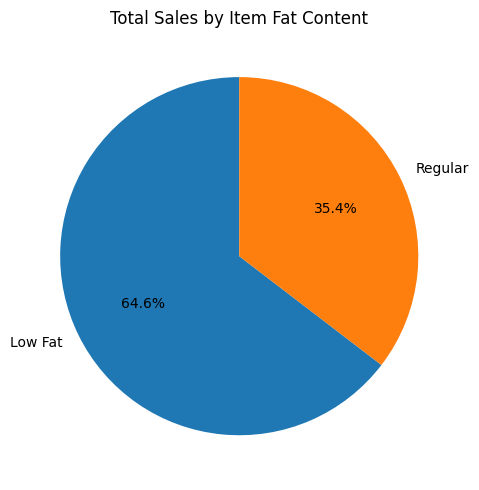

In [23]:
sales_by_fat['Total_Sales'].plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    figsize=(5, 5)
)

plt.title('Total Sales by Item Fat Content')
plt.ylabel('')
plt.tight_layout()
plt.show()

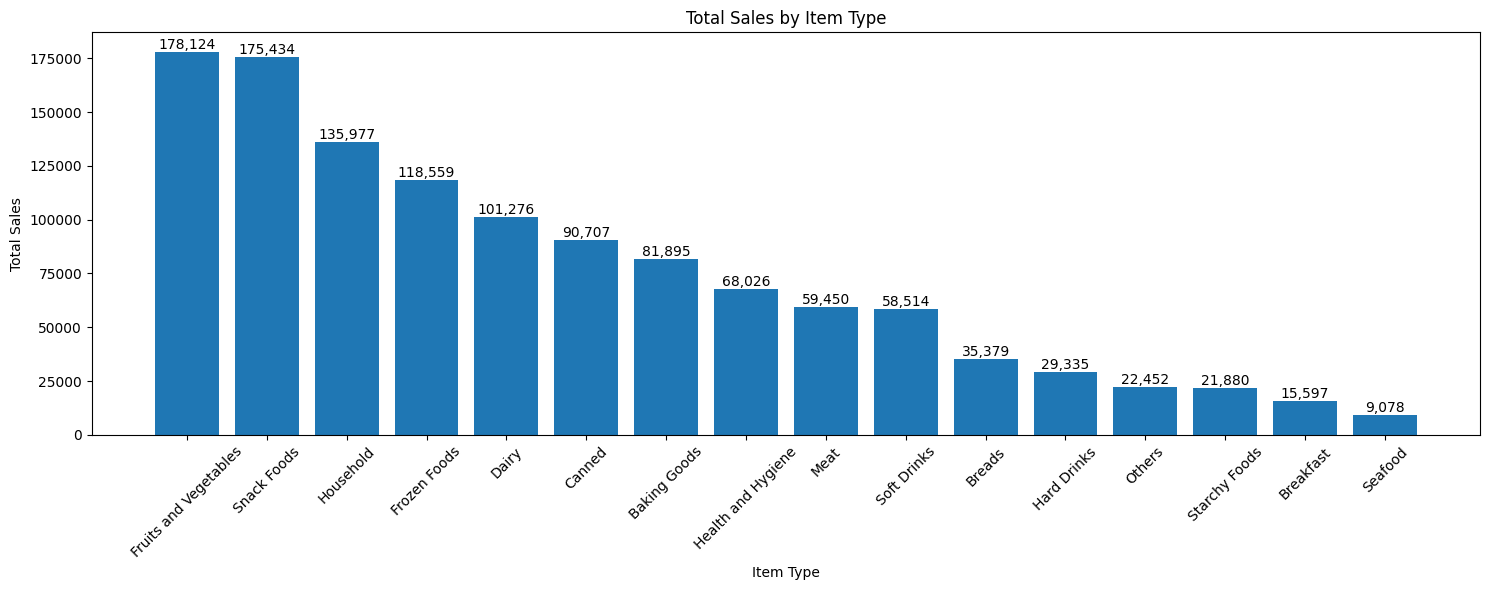

In [24]:

plt.figure(figsize=(15, 6))

bars = plt.bar(
    item_type_analysis.index,
    item_type_analysis['Total_Sales']
)

plt.title('Total Sales by Item Type')
plt.xlabel('Item Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():,.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

### **Fat Content By Outlet For Total Sales**


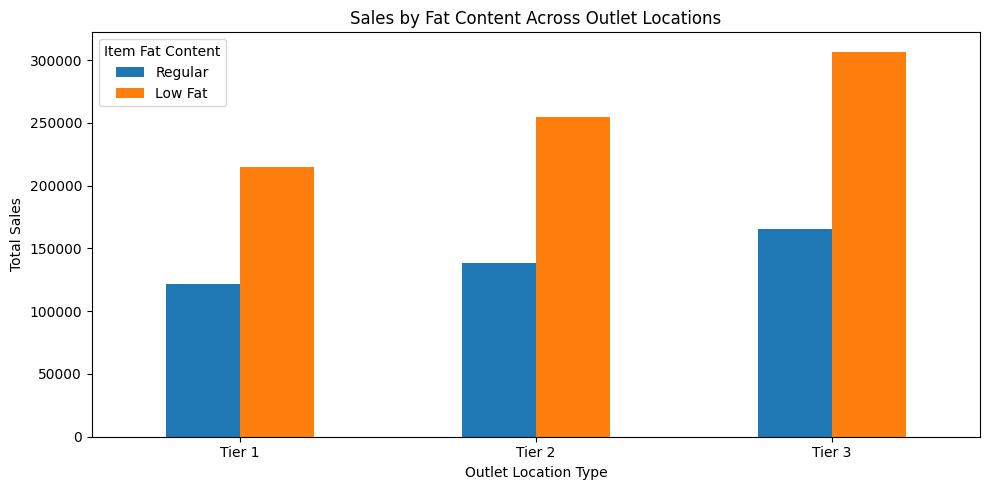

In [25]:
fat_by_location[['Regular', 'Low Fat']].plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Sales by Fat Content Across Outlet Locations')
plt.xlabel('Outlet Location Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.legend(title='Item Fat Content')

plt.tight_layout()
plt.show()

### **Total Sales By Outlet Establishment**

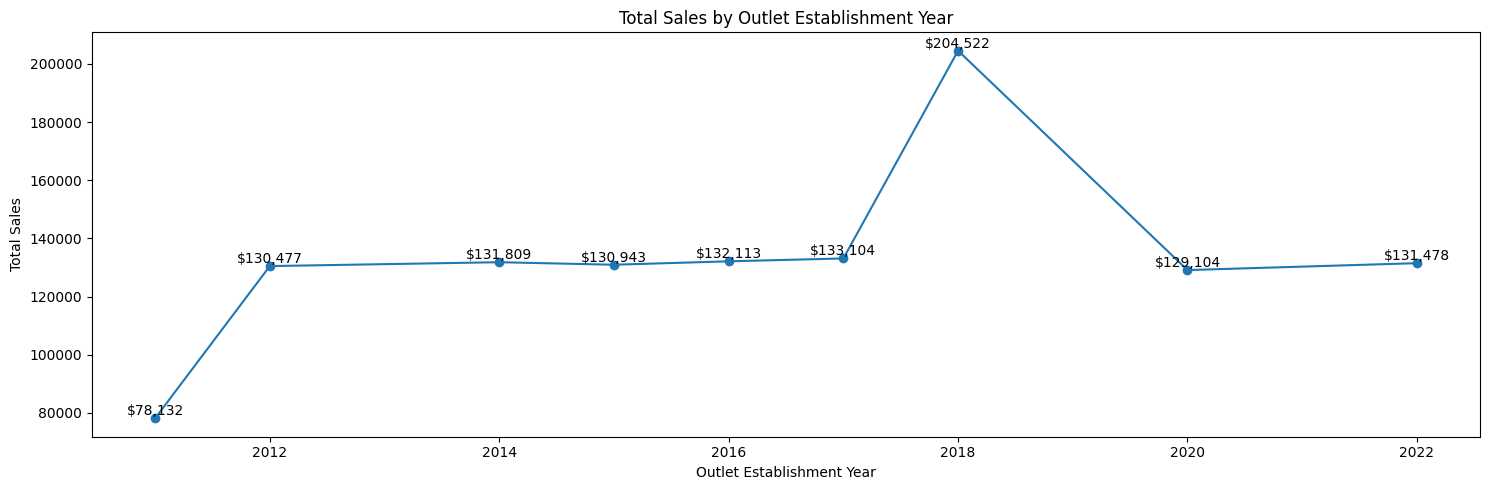

In [26]:
plt.figure(figsize=(15, 5))

plt.plot(
    sales_by_year.index,
    sales_by_year['Total_Sales'],
    marker='o'
)

plt.title('Total Sales by Outlet Establishment Year')
plt.xlabel('Outlet Establishment Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

for x, y in zip(
    sales_by_year.index,
    sales_by_year['Total_Sales']
):
    plt.text(
        x,
        y,
        f'${y:,.0f}',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

### **Sales By Outlet Size**

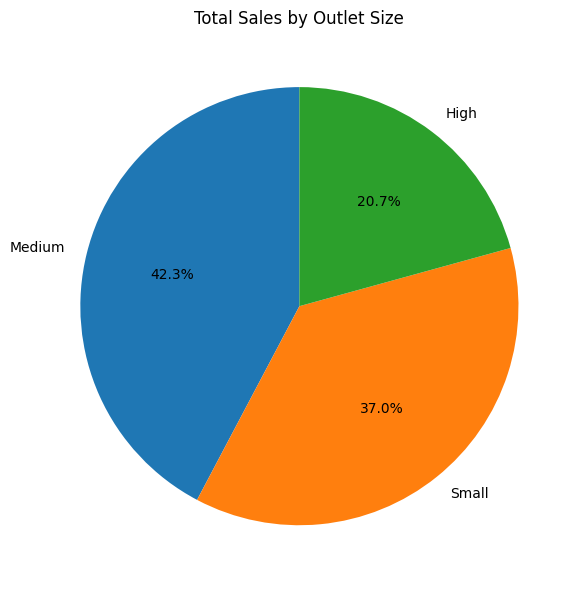

In [27]:
outlet_size_analysis['Total_Sales'].plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    figsize=(6, 6)
)

plt.title('Total Sales by Outlet Size')
plt.ylabel('')

plt.tight_layout()
plt.show()

### **Sales By Outlet Location**

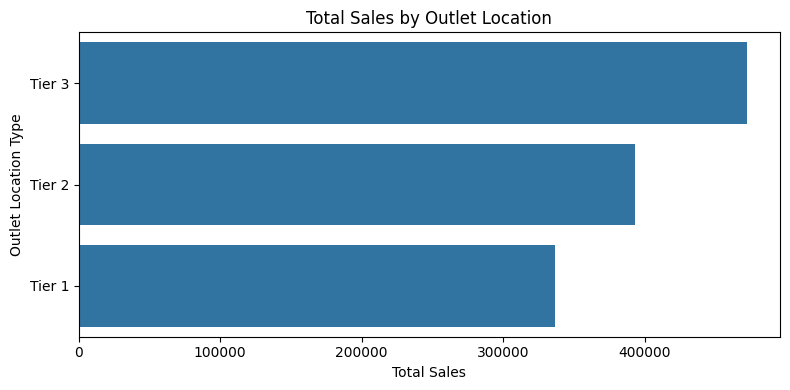

In [28]:
plt.figure(figsize=(8, 4))

sns.barplot(
    x='Total_Sales',
    y=outlet_location_analysis.index,
    data=outlet_location_analysis.reset_index()
)

plt.title('Total Sales by Outlet Location')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Location Type')

plt.tight_layout()
plt.show()

## TOTAL SALES BY OUTLET TYPE

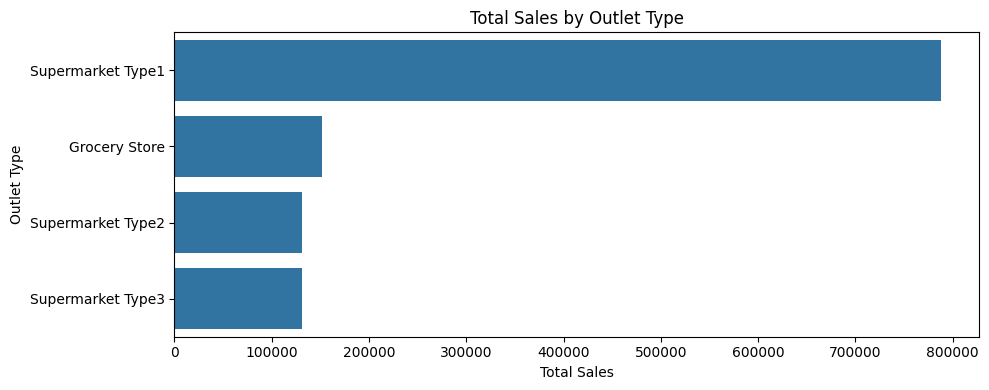

In [29]:
plt.figure(figsize=(10, 4))

sns.barplot(
    x='Total_Sales',
    y=outlet_type_analysis.index,
    data=outlet_type_analysis.reset_index()
)

plt.title('Total Sales by Outlet Type')
plt.xlabel('Total Sales')
plt.ylabel('Outlet Type')

plt.tight_layout()
plt.show()

# Key Business Insights & Recommendations

## Key Business Insights

### 1. Item Fat Content
Low Fat products generated approximately 64.6% of total sales, while Regular products accounted for approximately 35.4%. This indicates that Low Fat products represent the stronger sales segment in the analyzed dataset.

### 2. Product Performance
Fruits and Vegetables recorded the highest total sales, closely followed by Snack Foods. These two categories are the strongest contributors to product-level sales, while several smaller categories contribute a relatively limited share.

### 3. Outlet Location Performance
Tier 3 outlets generated the highest share of total sales at approximately 39.3%, followed by Tier 2 at 32.7% and Tier 1 at 28.0%, indicating differences in sales contribution across outlet location tiers.

### 4. Outlet Size Performance
Medium-sized outlets contributed the largest share of total sales at approximately 42.3%, followed by Small outlets at 37.0% and High-sized outlets at 20.7%.

### 5. Outlet Type Performance
Supermarket Type1 generated the largest share of total sales, significantly outperforming the other outlet formats in the analyzed dataset.

### 6. Item Visibility Observation
Grocery Stores recorded the highest average item visibility, while Supermarket Type3 recorded the lowest. However, this analysis is descriptive and does not establish a causal relationship between item visibility and sales.

## Business Recommendations

1. **Strengthen the Low Fat Product Portfolio**  
   Continue monitoring demand for Low Fat products and prioritize inventory availability for high-performing Low Fat categories.

2. **Prioritize High-Performing Product Categories**  
   Review inventory and assortment strategies for leading categories such as Fruits and Vegetables and Snack Foods to support continued sales performance.

3. **Evaluate High-Performing Outlet Formats**  
   Investigate the operational and financial characteristics of Supermarket Type1 outlets to understand the factors behind their stronger sales contribution.

4. **Review Outlet Size Performance**  
   Medium-sized outlets show the highest sales contribution and may deserve further evaluation when considering store planning, assortment, and capacity decisions.

5. **Investigate Item Visibility Opportunities**  
   Compare item visibility practices across outlet types and investigate whether visibility optimization may improve product exposure and performance, without assuming a causal relationship from the current descriptive analysis.

# Conclusion

This project used Python to clean, explore, and analyze Blinkit sales data across product and outlet dimensions.

The analysis covered data quality validation, missing-value treatment, KPI development, product performance, outlet performance, sales contribution, and exploratory visualization.

The results highlight differences in sales performance across product segments, outlet locations, outlet sizes, and outlet formats, providing a data-driven foundation for business investigation and decision-making.